# 02｜建模與評估：人潮預測與備餐建議

承接 `01_eda.ipynb` 的結論，這份 notebook 一步一步示範：

1. 依時間切分訓練集與測試集
2. 特徵工程
3. 比較 4 種人潮模型（含基準線）
4. 評估：預測 vs 實際、殘差、特徵重要性
5. 分位數迴歸：從「預測需求」到「建議備餐量」
6. 回測：AI 建議 vs 目前備餐方式
7. 結論

> 這裡的程式碼與 `foodcast/train.py` 相同邏輯，但拆成小步驟、加上圖表說明。
> 實際網頁使用的模型由 `python -m foodcast.train` 產生。
> ⚠️ 使用模擬資料；不同電腦的套件版本不同，數字可能有些微差異。

In [1]:
import sys
from pathlib import Path

# 讓 notebook 可以 import 專案的 foodcast 套件（notebook 在 notebooks/ 資料夾裡）
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字型：Windows 用微軟正黑體，Mac 用蘋方，Linux 用 Noto，依序找第一個有的
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Noto Sans CJK TC", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 負號正常顯示
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

from foodcast import config
from foodcast.train import load_data, time_split
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from foodcast.features import CROWD_FEATURES, DEMAND_CATEGORICAL, FEATURE_LABELS, crowd_X, demand_X

## 1. 依時間切分

時間序列資料**不能隨機切分**：隨機切會讓模型在訓練時看過「未來」的日子，
測試分數會太樂觀，實際上線時根本拿不到未來的資料。

In [2]:
crowd, demand = load_data()
train, test = time_split(crowd)
print(f"訓練：{train['date'].min():%Y-%m-%d} ~ {train['date'].max():%Y-%m-%d}，{len(train):,} 列")
print(f"測試：{test['date'].min():%Y-%m-%d} ~ {test['date'].max():%Y-%m-%d}，{len(test):,} 列（{test['date'].nunique()} 天）")

訓練：2024-09-01 ~ 2026-02-28，5,460 列
測試：2026-03-01 ~ 2026-06-30，1,220 列（122 天）


## 2. 特徵工程

`foodcast/features.py` 把原始欄位轉成模型的輸入。訓練和預測共用同一個函式，確保兩邊的特徵完全一致。

In [3]:
X_tr, y_tr = crowd_X(train), train["customers"]
X_te, y_te = crowd_X(test), test["customers"]
pd.DataFrame({"特徵": CROWD_FEATURES, "說明": [FEATURE_LABELS[f] for f in CROWD_FEATURES]}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12
特徵,meal_code,weekday,is_weekend,is_holiday,month,in_semester,week,exam_week,pre_final,temp,rain_mm,has_event,slot_hour
說明,午餐/晚餐,星期幾,是否週末,國定假日,月份,是否學期中,學期週次,考試週,期末考前一週,氣溫,雨量,校園活動,用餐時段


## 3. 模型比較

| 模型 | 為什麼放進來比較 |
|---|---|
| 歷史平均（基準線） | 「同星期幾、同時段的平均」：最簡單的方法，任何模型都要贏過它才有意義 |
| 線性迴歸 | 最基本的 ML 模型，驗證 EDA 的推測：關係是非線性的 |
| 隨機森林 | 多棵決策樹投票，能學到非線性與交互作用 |
| 梯度提升樹 | 一棵接一棵修正前面的錯誤，通常在表格資料上表現最好 |

In [4]:
def scores(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}

preds = {}
key = ["weekday", "meal", "slot"]
avg = train.groupby(key)["customers"].mean().rename("p")
preds["歷史平均（基準線）"] = test.join(avg, on=key)["p"].fillna(y_tr.mean()).to_numpy()

models = {
    "線性迴歸": LinearRegression(),
    "隨機森林": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=config.RANDOM_SEED, n_jobs=-1),
    "梯度提升樹": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=config.RANDOM_SEED),
}
for name, m in models.items():
    preds[name] = m.fit(X_tr, y_tr).predict(X_te)

result = pd.DataFrame({n: scores(y_te, p) for n, p in preds.items()}).T.round(3)
result

,MAE,RMSE,R²
歷史平均（基準線）,43.044,58.679,0.737
線性迴歸,64.073,87.204,0.418
隨機森林,17.938,25.268,0.951
梯度提升樹,16.902,24.107,0.956


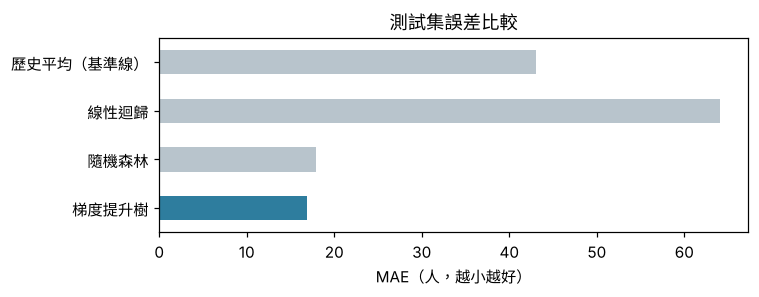

In [5]:
ax = result["MAE"].plot(kind="barh", figsize=(7, 2.8), color=["#B8C4CC", "#B8C4CC", "#B8C4CC", "#2E7D9E"])
ax.set_xlabel("MAE（人，越小越好）")
ax.set_title("測試集誤差比較")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**解讀**：
- **線性迴歸比基準線還差**：它假設「時段每晚一小時，人數固定增加多少」，但實際是 12:00 最多、前後遞減的山形，直線畫不出來。
- **樹模型的 MAE 只有基準線的一半不到**：它們能學到「考試週 × 晚餐」這類交互作用。
- 梯度提升樹略勝隨機森林，因此作為最終模型。

## 4. 評估最佳模型

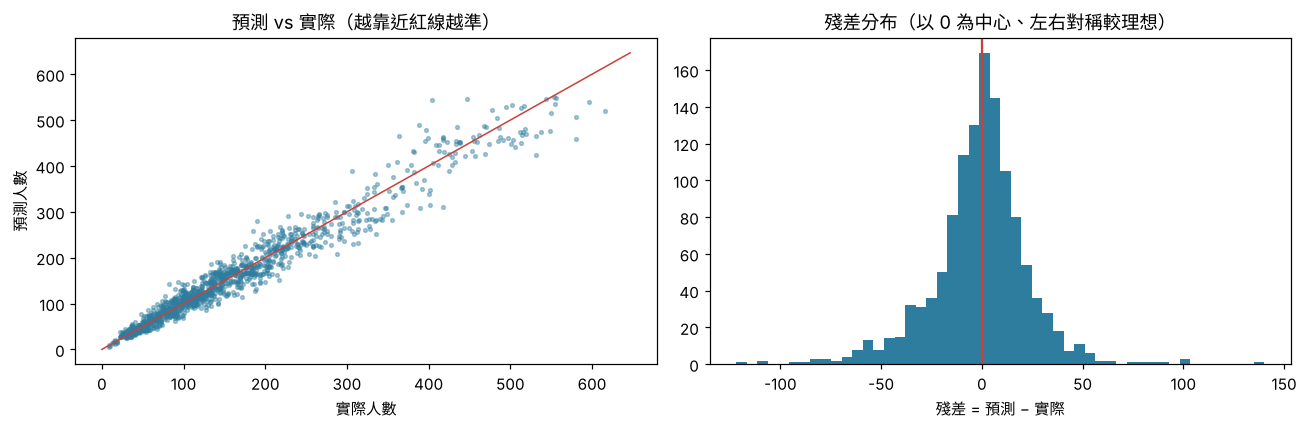

In [6]:
best = models["梯度提升樹"]
p = preds["梯度提升樹"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.scatter(y_te, p, s=6, alpha=0.4, color="#2E7D9E")
lim = [0, max(y_te.max(), p.max()) * 1.05]
ax.plot(lim, lim, color="#C8423B", lw=1)
ax.set_xlabel("實際人數")
ax.set_ylabel("預測人數")
ax.set_title("預測 vs 實際（越靠近紅線越準）")

ax = axes[1]
ax.hist(p - y_te, bins=50, color="#2E7D9E")
ax.axvline(0, color="#C8423B")
ax.set_xlabel("殘差 = 預測 − 實際")
ax.set_title("殘差分布（以 0 為中心、左右對稱較理想）")
plt.tight_layout()
plt.show()

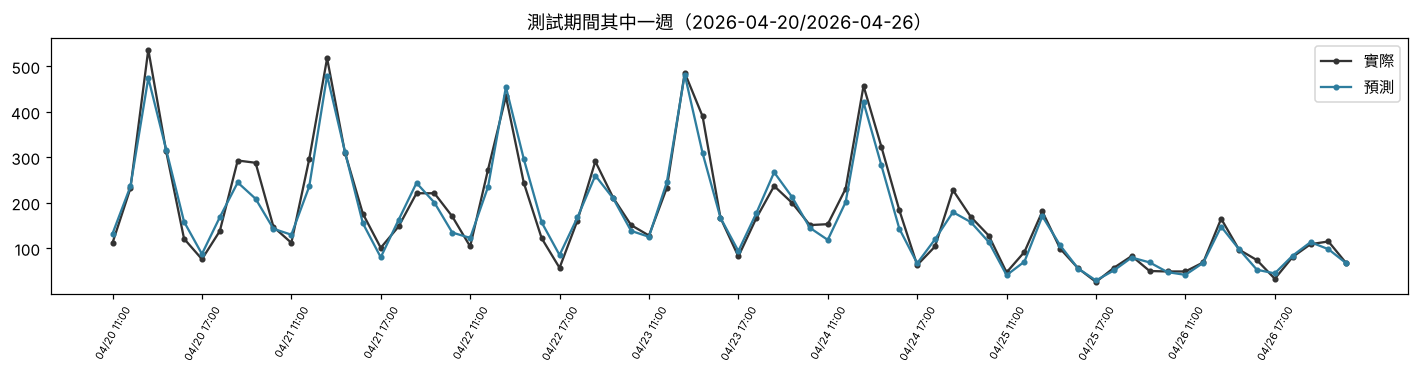

In [7]:
# 測試期間任選一週，看看預測曲線有沒有跟上實際變化
wk = test["date"].dt.to_period("W").astype(str).unique()[8]
mask = (test["date"].dt.to_period("W").astype(str) == wk).to_numpy()
sub = test[mask].assign(pred=p[mask])
labels = sub["date"].dt.strftime("%m/%d ") + sub["slot"]

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(range(len(sub)), sub["customers"], marker="o", ms=3, label="實際", color="#333")
ax.plot(range(len(sub)), sub["pred"], marker="o", ms=3, label="預測", color="#2E7D9E")
ax.set_xticks(range(0, len(sub), 5), labels.iloc[::5], rotation=60, fontsize=7)
ax.set_title(f"測試期間其中一週（{wk}）")
ax.legend()
plt.tight_layout()
plt.show()

### 特徵重要性（置換重要性）

把某個特徵的值**隨機打亂**，如果模型誤差變大很多，代表模型很依賴這個特徵。
這個方法適用於任何模型，而且是在測試集上計算，比樹模型內建的重要性更可靠。

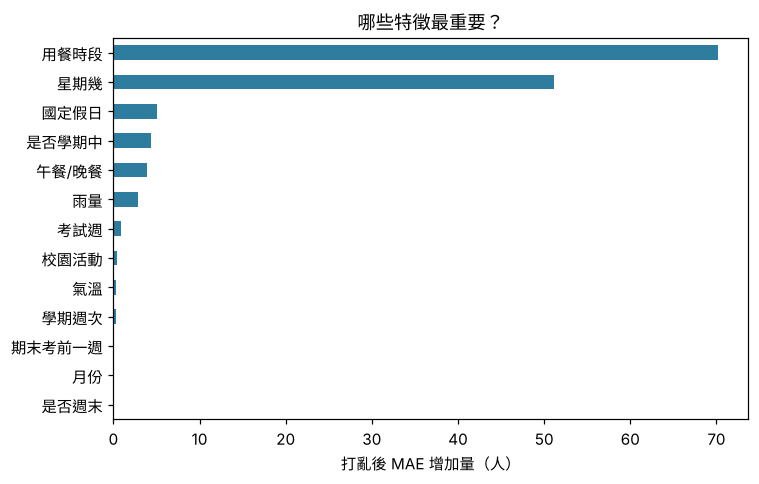

In [8]:
imp = permutation_importance(best, X_te, y_te, n_repeats=5, random_state=config.RANDOM_SEED,
                             scoring="neg_mean_absolute_error")
imp_s = pd.Series(imp.importances_mean, index=[FEATURE_LABELS[f] for f in CROWD_FEATURES]).sort_values()
ax = imp_s.plot(kind="barh", figsize=(7, 4.5), color="#2E7D9E")
ax.set_xlabel("打亂後 MAE 增加量（人）")
ax.set_title("哪些特徵最重要？")
plt.tight_layout()
plt.show()

**解讀**：用餐時段、星期幾最重要，和 EDA 看到的規律一致。
行事曆特徵（假日、學期中）和雨量也有貢獻，證明加入這些特徵是值得的。

## 5. 分位數迴歸：從「預測需求」到「建議備餐量」

一般迴歸預測的是「平均會賣幾份」。如果店家剛好準備平均值，大約一半的日子會賣完。

**分位數迴歸**改成預測「第 q 分位數」：例如 q = 0.7 代表「有 70% 的機率需求不會超過這個數字」。
店家可以依照自己能接受的風險選 q，這就是作業研究裡的**報童問題 (Newsvendor Problem)**。

In [9]:
d_tr, d_te = time_split(demand)
Xd_tr, Xd_te = demand_X(d_tr), demand_X(d_te)
qmodels = {}
for q in [0.1, 0.5, 0.7, 0.9]:
    qmodels[q] = HistGradientBoostingRegressor(
        loss="quantile", quantile=q, max_iter=400, learning_rate=0.05,
        categorical_features=DEMAND_CATEGORICAL, random_state=config.RANDOM_SEED,
    ).fit(Xd_tr, d_tr["demand"])
    d_te[f"q{int(q * 100)}"] = qmodels[q].predict(Xd_te).clip(min=0)

# 檢查：實際需求落在第 q 分位數以下的比例，應該接近 q
check = {f"q={q}": f"{(d_te['demand'] <= d_te[f'q{int(q * 100)}']).mean():.1%}" for q in qmodels}
pd.Series(check, name="實際需求 ≤ 預測值 的比例")

q=0.1    12.9%
q=0.5    49.0%
q=0.7    64.9%
q=0.9    83.9%
Name: 實際需求 ≤ 預測值 的比例, dtype: str

**校準檢查（calibration）**：理想上，「實際需求 ≤ 第 q 分位數預測」的比例應該等於 q。

- 中位數（q=0.5）通常很接近 50%。
- 高分位數（0.7、0.9）的實際比例**略低於 q**，代表模型對需求特別高的日子估得**偏保守不足**，實際賣完的機率比名目上高一些。
- 可能原因：極端高需求的日子（考試週＋下雨）在訓練資料中較少，梯度提升樹對分布尾端的估計比較不準。
- 改善方向：用驗證期間的資料做**校正**（例如 conformal prediction），或把預設服務水準調高一級。

這個檢查說明「q=0.7」是**模型的目標**，不是保證，上線後要持續用實際銷量檢查。

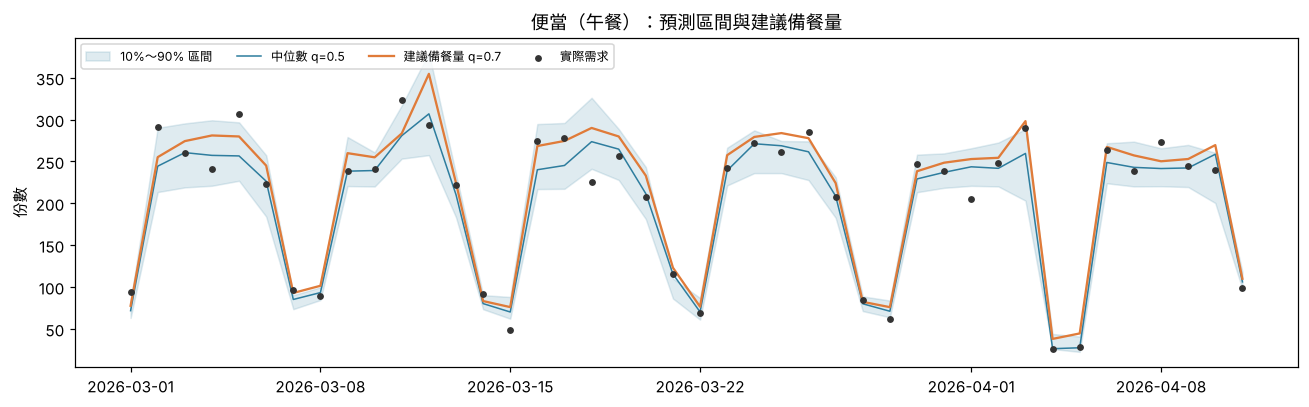

In [10]:
# 以「便當、午餐」為例，畫出測試期間前 6 週的預測區間
s = d_te[(d_te["dish"] == "便當") & (d_te["meal"] == "午餐")].sort_values("date").head(42)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(s["date"], s["q10"], s["q90"], color="#2E7D9E", alpha=0.15, label="10%～90% 區間")
ax.plot(s["date"], s["q50"], color="#2E7D9E", lw=1, label="中位數 q=0.5")
ax.plot(s["date"], s["q70"], color="#E07B39", lw=1.5, label="建議備餐量 q=0.7")
ax.scatter(s["date"], s["demand"], s=12, color="#333", zorder=3, label="實際需求")
ax.set_title("便當（午餐）：預測區間與建議備餐量")
ax.set_ylabel("份數")
ax.legend(ncol=4, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**解讀**：
- 週末區間變窄、數字變小，模型知道週末人少。
- 橘線（q=0.7）在多數日子高於黑點（實際需求），但仍有一些日子需求超過建議量：這正是「70% 服務水準」的意思，不是每天都保證夠。

## 6. 回測：AI 建議 vs 目前備餐方式

「目前方式」模擬店家的經驗法則：**前兩週同一天的銷量 × 1.15**。
在整個測試期間逐日比較兩種方式的剩食與缺貨。

In [11]:
waste_kg = d_te["dish"].map({k: v["waste_kg"] for k, v in config.DISHES.items()})

def evaluate(prep):
    leftover = (prep - d_te["demand"]).clip(lower=0)
    stockout = (d_te["demand"] - prep).clip(lower=0)
    return {"剩食 (kg)": (leftover * waste_kg).sum(), "需求滿足率 (%)": 100 * (1 - stockout.sum() / d_te["demand"].sum())}

rows = {"目前方式": evaluate(d_te["prep_current"])}
for q in [0.5, 0.7, 0.9]:
    rows[f"AI q={q}"] = evaluate(np.ceil(d_te[f"q{int(q * 100)}"]))
bt = pd.DataFrame(rows).T
bt["剩食減少 (%)"] = 100 * (1 - bt["剩食 (kg)"] / bt.loc["目前方式", "剩食 (kg)"])
bt.round(1)

,剩食 (kg),需求滿足率 (%),剩食減少 (%)
目前方式,16261.4,94.8,0.0
AI q=0.5,3543.3,94.8,78.2
AI q=0.7,5991.0,97.0,63.2
AI q=0.9,11311.5,99.0,30.4


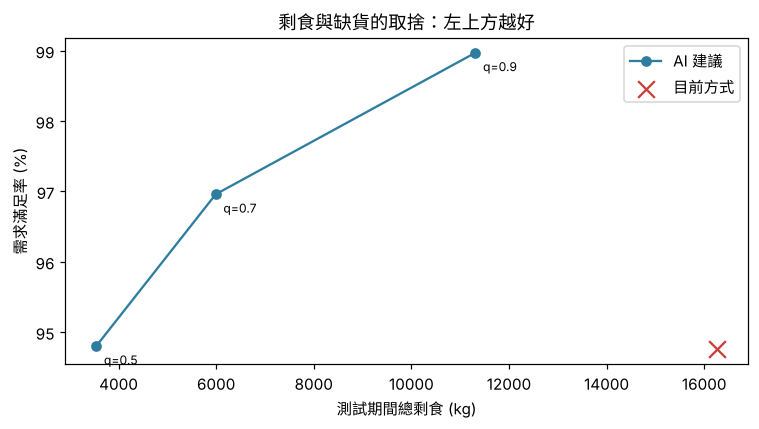

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ai = bt.drop(index="目前方式")
ax.plot(ai["剩食 (kg)"], ai["需求滿足率 (%)"], marker="o", color="#2E7D9E", label="AI 建議")
for name, r in ai.iterrows():
    ax.annotate(name.replace("AI ", ""), (r["剩食 (kg)"], r["需求滿足率 (%)"]), textcoords="offset points", xytext=(5, -12), fontsize=8)
cur = bt.loc["目前方式"]
ax.scatter(cur["剩食 (kg)"], cur["需求滿足率 (%)"], marker="x", s=120, color="#C8423B", label="目前方式", zorder=3)
ax.set_xlabel("測試期間總剩食 (kg)")
ax.set_ylabel("需求滿足率 (%)")
ax.set_title("剩食與缺貨的取捨：左上方越好")
ax.legend()
plt.tight_layout()
plt.show()

## 7. 結論

1. **模型選擇**：EDA 發現人潮是非線性、有交互作用的 → 樹模型大幅勝過線性迴歸與基準線，梯度提升樹最佳。
2. **評估方式**：依時間切分，測試期間是模型完全沒看過的下學期，結果比較可信。
3. **可解釋**：置換重要性顯示時段、星期幾、行事曆、天氣都有貢獻，和 EDA 的觀察一致。
4. **實際價值**：分位數迴歸讓預測變成可操作的「建議備餐量」；回測顯示在各種服務水準下，剩食都比目前方式少，滿足率也較高或相近。
5. **限制**：以上皆為**模擬資料**的結果。網頁的「上傳真實資料」功能可以換成學餐 POS 資料後重新訓練，屆時需要重新評估。

延伸閱讀：網頁「模型分析」頁有超參數調整（時間序列交叉驗證）與錯誤分析。